## Netflix customer churn

Data source: https://www.kaggle.com/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics

What factors can predict Netflix customer churn?

### Initial setup and data ingestion

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme()
%matplotlib inline
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
netflix = pd.read_csv('data/netflix_customer_churn.csv')

### Exploratory analysis

In [3]:
netflix.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [4]:
netflix.tail()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi
4999,82aeef39-ddb0-40ad-bae1-5c436e0cf042,57,Male,Basic,1.62,17,Africa,Mobile,8.99,1,Crypto,2,0.09,Action


In [5]:
netflix.describe()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'watch_hours'}>,
        <Axes: title={'center': 'last_login_days'}>],
       [<Axes: title={'center': 'monthly_fee'}>,
        <Axes: title={'center': 'churned'}>,
        <Axes: title={'center': 'number_of_profiles'}>],
       [<Axes: title={'center': 'avg_watch_time_per_day'}>, <Axes: >,
        <Axes: >]], dtype=object)

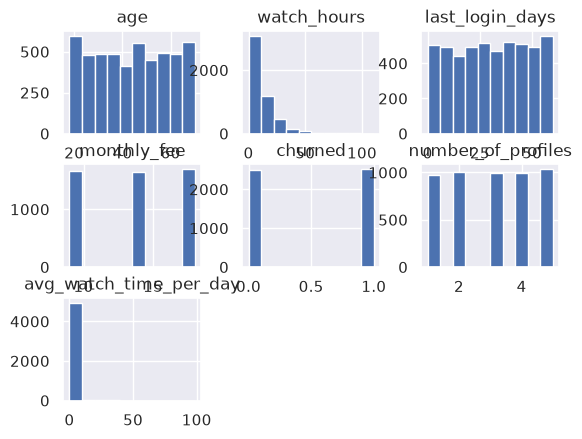

In [6]:
netflix.hist()

<Axes: xlabel='monthly_fee', ylabel='churned'>

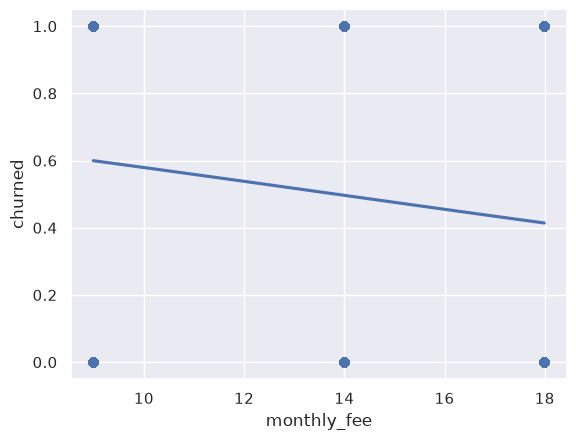

In [7]:
sns.regplot(x='monthly_fee',y='churned',ci=None,logistic=True,data=netflix)

<Axes: xlabel='watch_hours', ylabel='churned'>

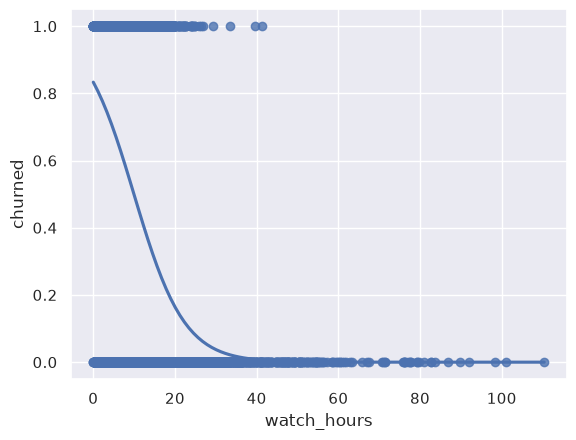

In [8]:
sns.regplot(x='watch_hours',y='churned',ci=None,logistic=True,data=netflix)

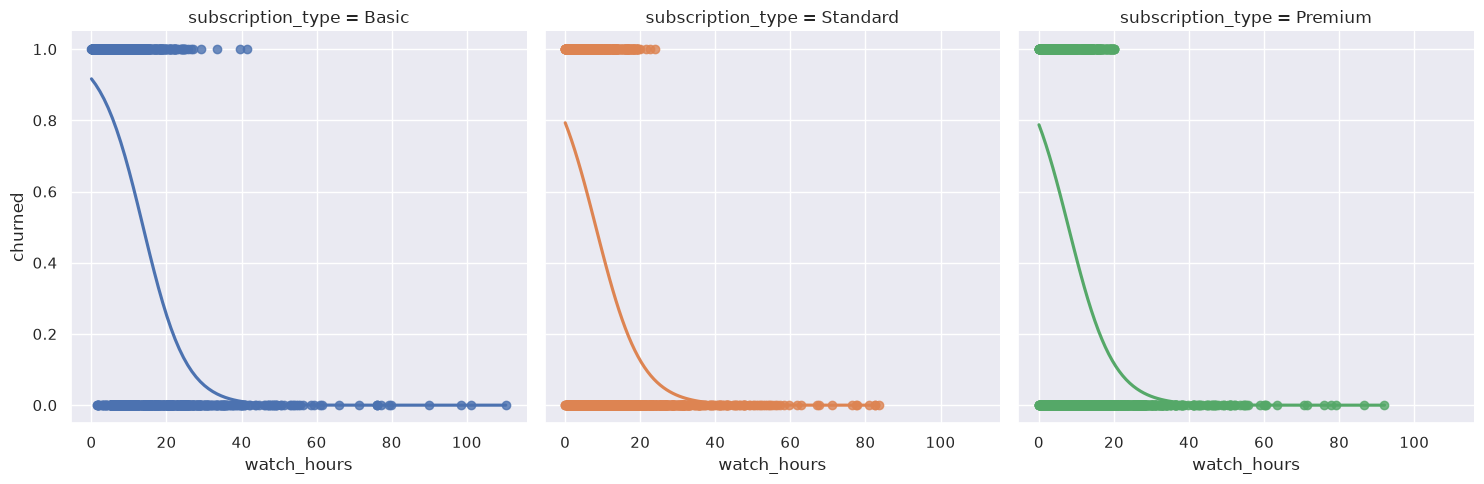

In [9]:
sns.lmplot(x='watch_hours',y='churned',ci=None,logistic=True,col='subscription_type',hue='subscription_type',data=netflix)

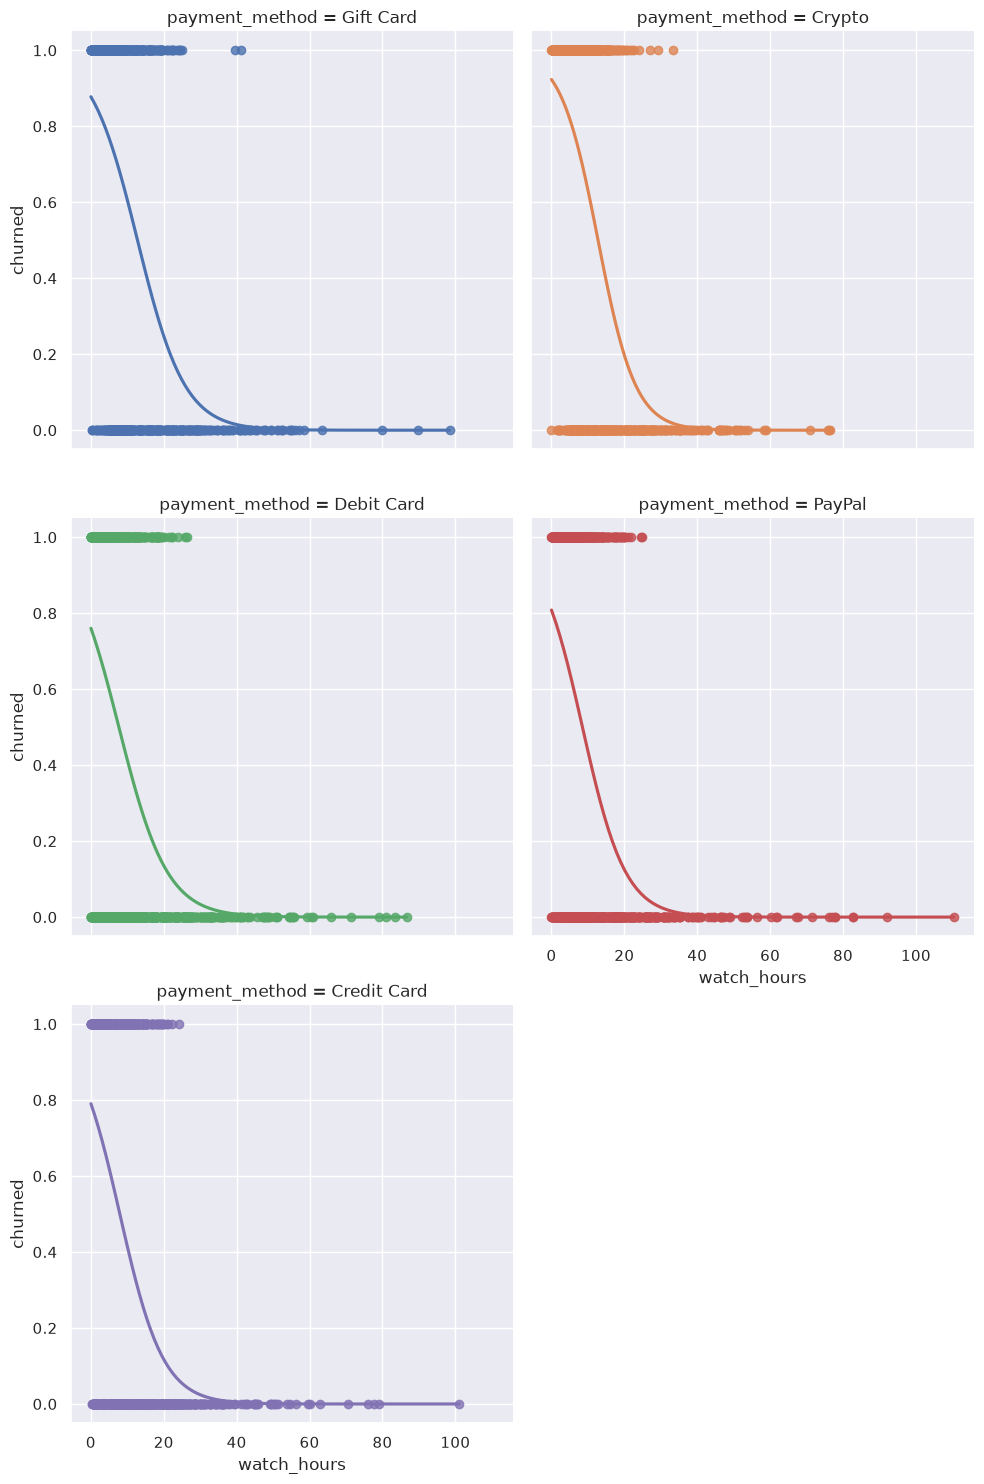

In [10]:
sns.lmplot(x='watch_hours',y='churned',ci=None,logistic=True,col='payment_method',col_wrap=2,hue='payment_method',data=netflix)

<Axes: xlabel='last_login_days', ylabel='churned'>

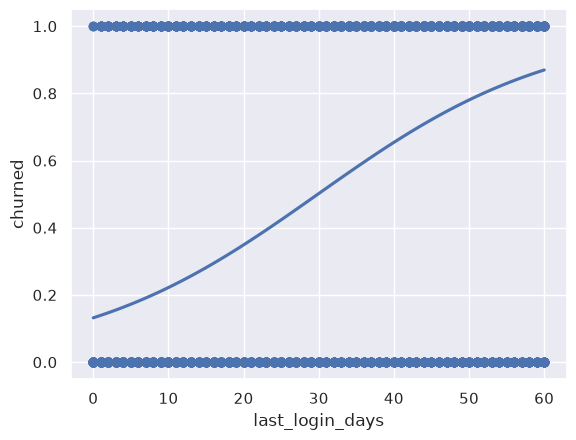

In [11]:
sns.regplot(x='last_login_days',y='churned',ci=None,logistic=True,data=netflix)

<Axes: xlabel='age', ylabel='churned'>

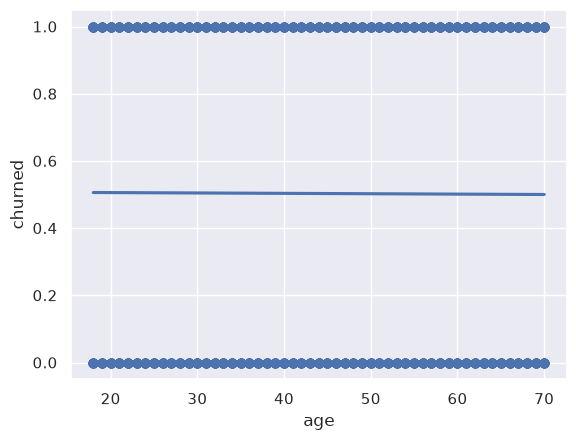

In [12]:
sns.regplot(x='age',y='churned',ci=None,logistic=True,data=netflix)

<Axes: xlabel='number_of_profiles', ylabel='churned'>

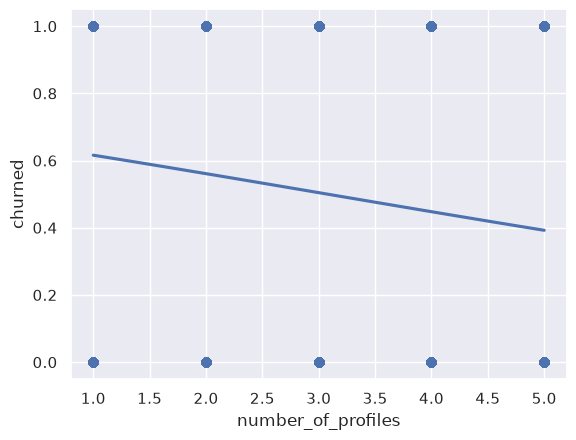

In [13]:
sns.regplot(x='number_of_profiles',y='churned',ci=None,logistic=True,data=netflix)

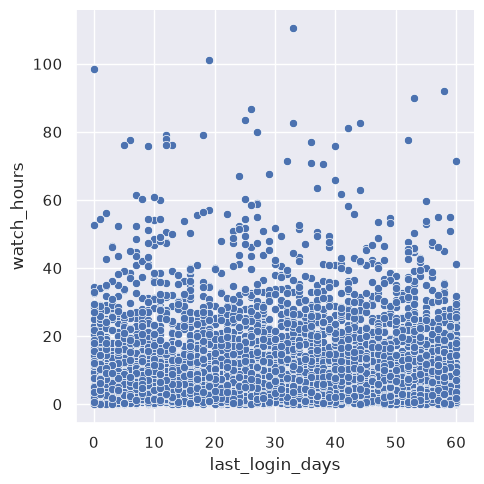

In [14]:
sns.relplot(x='last_login_days',y='watch_hours',data=netflix)

<Axes: xlabel='last_login_days', ylabel='watch_hours'>

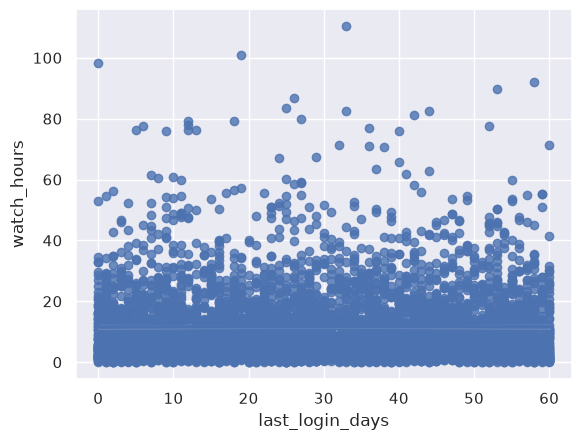

In [15]:
sns.regplot(x='last_login_days',y='watch_hours',data=netflix)

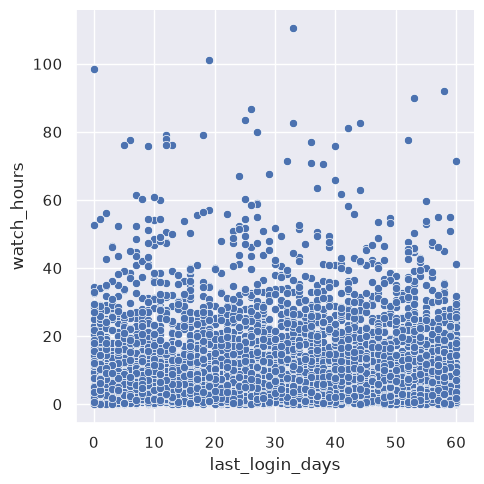

In [16]:
sns.relplot(x='last_login_days',y='watch_hours',data=netflix)

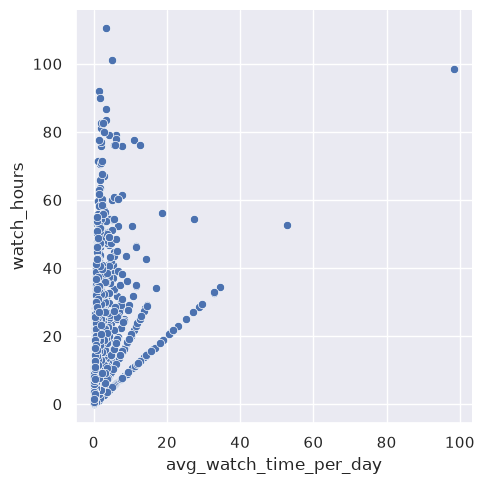

In [17]:
sns.relplot(x='avg_watch_time_per_day',y='watch_hours',data=netflix)

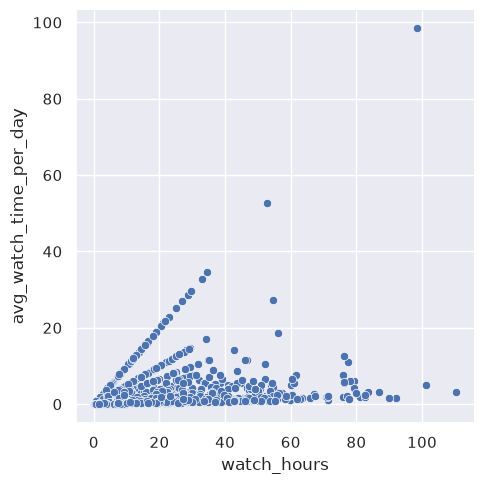

In [18]:
sns.relplot(x='watch_hours',y='avg_watch_time_per_day',data=netflix)

<Axes: xlabel='watch_hours', ylabel='avg_watch_time_per_day'>

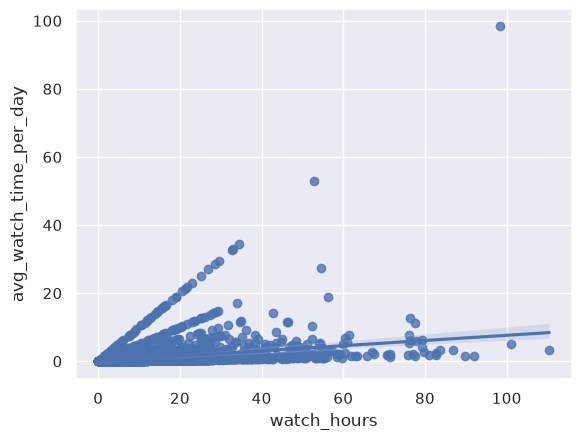

In [19]:
sns.regplot(x='watch_hours',y='avg_watch_time_per_day',data=netflix)

<Axes: xlabel='watch_hours', ylabel='avg_watch_time_per_day'>

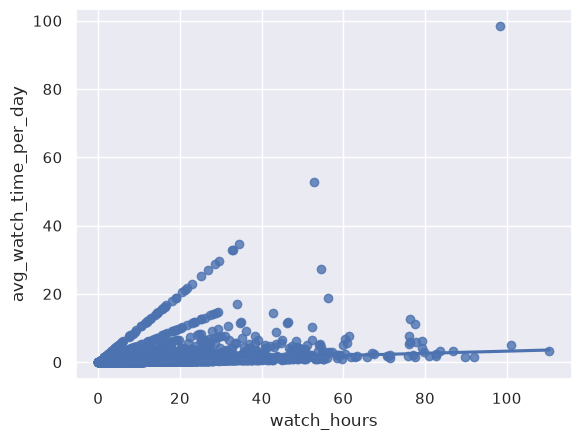

In [20]:
sns.regplot(x='watch_hours',y='avg_watch_time_per_day',robust=True,ci=False,data=netflix)

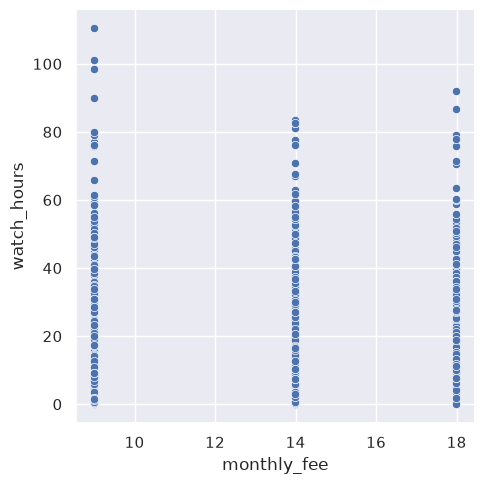

In [21]:
sns.relplot(x='monthly_fee',y='watch_hours',data=netflix)

<Axes: xlabel='monthly_fee', ylabel='watch_hours'>

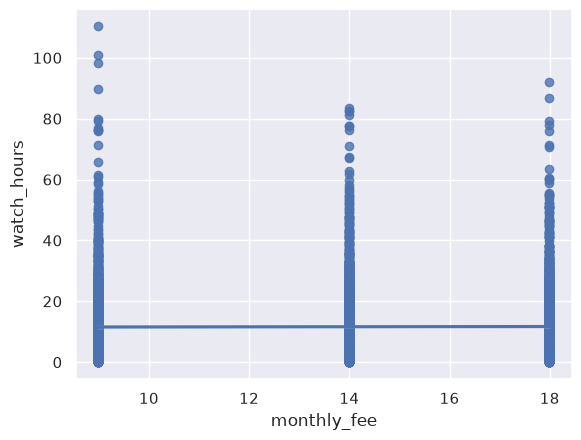

In [22]:
sns.regplot(x='monthly_fee',y='watch_hours',data=netflix)

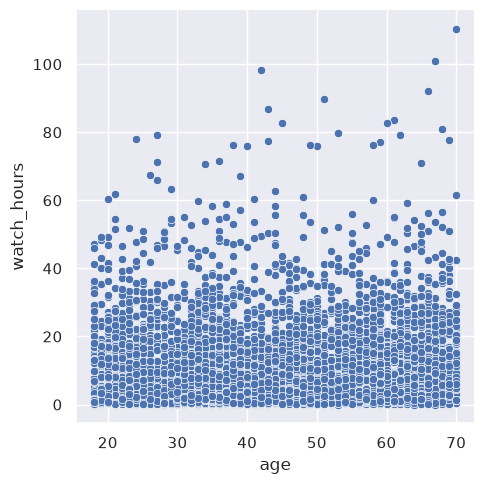

In [23]:
sns.relplot(x='age',y='watch_hours',data=netflix)

<Axes: xlabel='age', ylabel='watch_hours'>

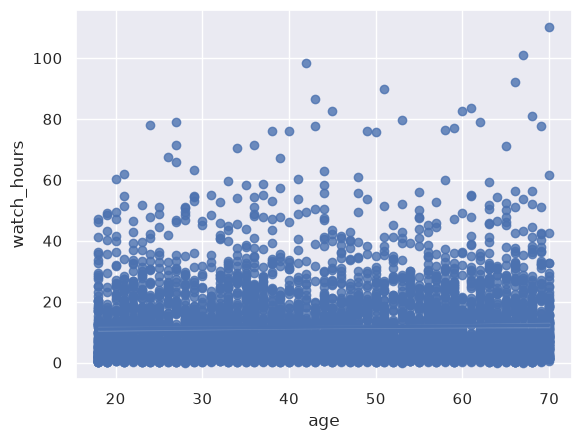

In [24]:
sns.regplot(x='age',y='watch_hours',data=netflix)

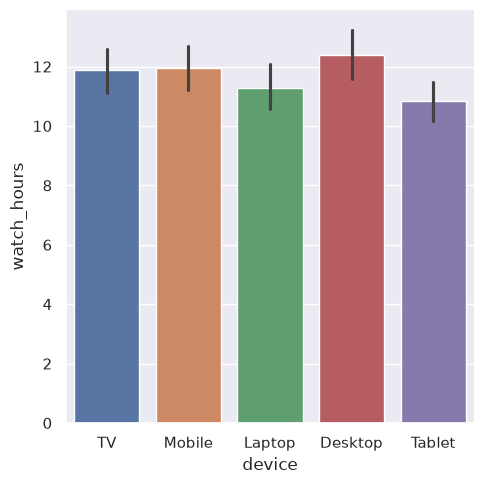

In [25]:
sns.catplot(x='device',y='watch_hours',kind='bar',hue='device',data=netflix)

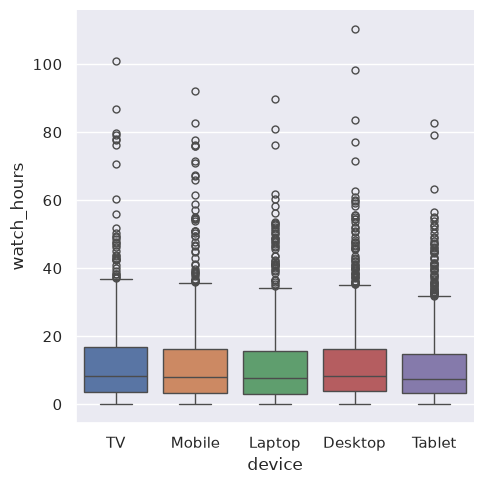

In [26]:
sns.catplot(x='device',y='watch_hours',kind='box',hue='device',data=netflix)

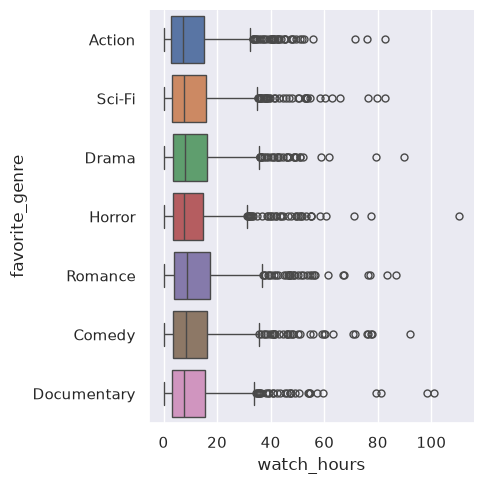

In [27]:
sns.catplot(y='favorite_genre',x='watch_hours',kind='box',hue='favorite_genre',data=netflix)

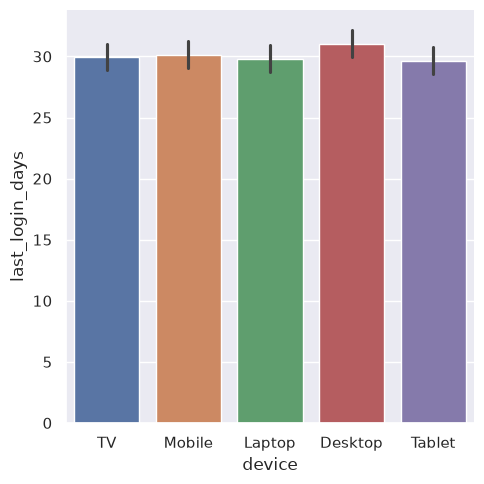

In [28]:
sns.catplot(x='device',y='last_login_days',kind='bar',hue='device',data=netflix)

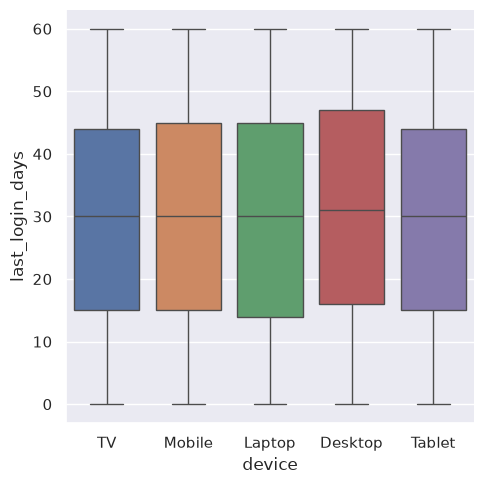

In [29]:
sns.catplot(x='device',y='last_login_days',kind='box',hue='device',data=netflix)

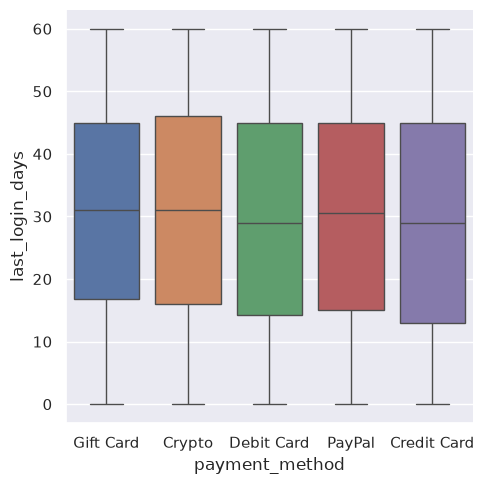

In [30]:
sns.catplot(x='payment_method',y='last_login_days',kind='box',hue='payment_method',data=netflix)

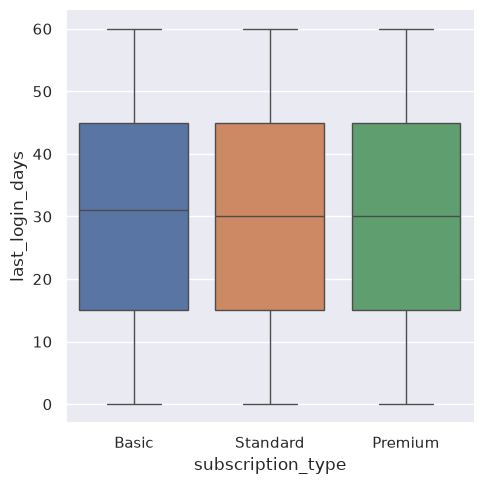

In [31]:
sns.catplot(x='subscription_type',y='last_login_days',kind='box',hue='subscription_type',data=netflix)

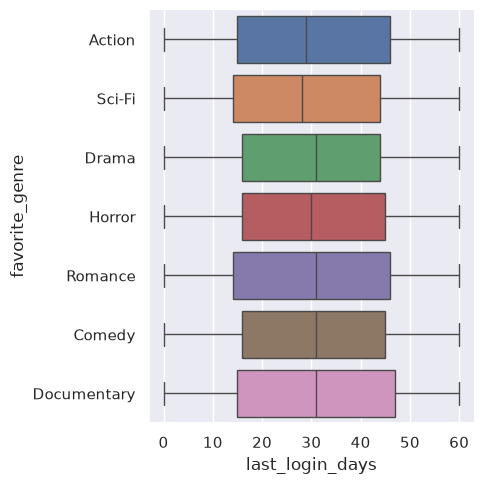

In [32]:
sns.catplot(y='favorite_genre',x='last_login_days',kind='box',hue='favorite_genre',data=netflix)

### Modeling

In [33]:
results = smf.logit('churned ~ age + watch_hours + last_login_days + monthly_fee + number_of_profiles + avg_watch_time_per_day', data=netflix).fit()
results.summary()

Optimization terminated successfully.
         Current function value: 0.260600
         Iterations 11


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                churned   No. Observations:                 5000
Model:                          Logit   Df Residuals:                     4993
Method:                           MLE   Df Model:                            6
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.6240
Time:                        11:20:18   Log-Likelihood:                -1303.0
converged:                       True   LL-Null:                       -3465.6
Covariance Type:            nonrobust   LLR p-value:                     0.000
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  5.6567      0.349     16.209      0.000       4.973       6.341
age                        0.0030      0.003      0.946      0.344      -0.003       0.009
watch_hours               -0.2279      0.017    -13.217      0.000      -0.262      -0.194
last_login_days            0.1014      0.006     15.993      0.000       0.089       0.114
monthly_fee               -0.2283      0.015    -15.407      0.000      -0.257      -0.199
number_of_profiles        -0.7223      0.040    -17.994      0.000      -0.801      -0.644
avg_watch_time_per_day    -3.3517      0.449     -7.468      0.000      -4.231      -2.472
==========================================================================================

Possibly complete quasi-separation: A fraction 0.10 of observations can be
perfectly predicted. This might indicate that there is complete
quasi-separation. In this case some parameters will not be identified.
"""

The model seems to have a good fit. As I suspected from the plot, age doe not seem to be a significant predictor of churn. The biggest positive predictor of churn seems to be the time since last logging in and the biggest negative predictor in the number of profiles.

In [34]:
results = smf.logit('churned ~ watch_hours + last_login_days + monthly_fee + number_of_profiles + avg_watch_time_per_day', data=netflix).fit()
results.summary()

Optimization terminated successfully.
         Current function value: 0.260690
         Iterations 11


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                churned   No. Observations:                 5000
Model:                          Logit   Df Residuals:                     4994
Method:                           MLE   Df Model:                            5
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.6239
Time:                        11:20:19   Log-Likelihood:                -1303.4
converged:                       True   LL-Null:                       -3465.6
Covariance Type:            nonrobust   LLR p-value:                     0.000
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  5.7828      0.323     17.883      0.000       5.149       6.417
watch_hours               -0.2280      0.017    -13.230      0.000      -0.262      -0.194
last_login_days            0.1014      0.006     16.010      0.000       0.089       0.114
monthly_fee               -0.2283      0.015    -15.415      0.000      -0.257      -0.199
number_of_profiles        -0.7216      0.040    -17.981      0.000      -0.800      -0.643
avg_watch_time_per_day    -3.3389      0.448     -7.450      0.000      -4.217      -2.460
==========================================================================================

Possibly complete quasi-separation: A fraction 0.10 of observations can be
perfectly predicted. This might indicate that there is complete
quasi-separation. In this case some parameters will not be identified.
"""

In [35]:
device_lm = smf.ols('last_login_days ~ C(device)', data=netflix).fit()

In [36]:
device_lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        last_login_days   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.8732
Date:                Tue, 20 Oct 2026   Prob (F-statistic):              0.479
Time:                        11:20:19   Log-Likelihood:                -21414.
No. Observations:                5000   AIC:                         4.284e+04
Df Residuals:                    4995   BIC:                         4.287e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              30.9821      0.569     54.424      0.000      29.866      32.098
C(device)[T.Laptop]    -1.2048      0.794     -1.518      0.129      -2.761       0.351
C(device)[T.Mobile]    -0.8436      0.794     -1.063      0.288      -2.400       0.713
C(device)[T.TV]        -1.0123      0.796     -1.272      0.204      -2.573       0.548
C(device)[T.Tablet]    -1.3332      0.786     -1.697      0.090      -2.874       0.207
==============================================================================
Omnibus:                     3875.742   Durbin-Watson:                   1.995
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              295.229
Skew:                          -0.027   Prob(JB):                     7.80e-65
Kurtosis:                       1.811   Cond. No.                         5.97
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

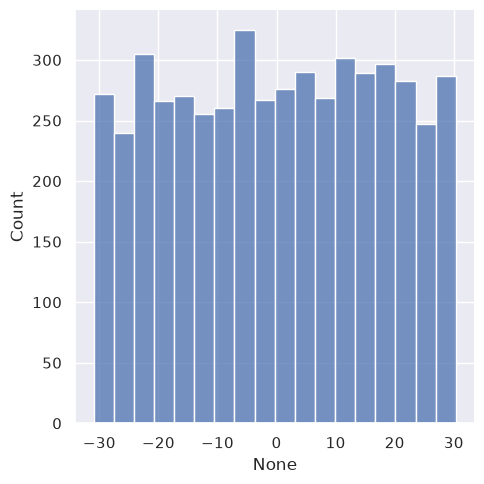

In [37]:
sns.displot(x=device_lm.resid)

Since the residuals don't appear to be normally distributed, I'll use the Kruskal-Wallis test for the ANOVA.

In [38]:
device = [group['last_login_days'] for name,group in netflix.groupby('device')]
stats.kruskal(*device)

KruskalResult(statistic=np.float64(3.5374774524400667), pvalue=np.float64(0.4722027440186439))

In [39]:
payment_lm = smf.ols('last_login_days ~ C(payment_method)', data=netflix).fit()

In [40]:
payment_lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        last_login_days   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.299
Date:                Tue, 20 Oct 2026   Prob (F-statistic):              0.268
Time:                        11:20:19   Log-Likelihood:                -21413.
No. Observations:                5000   AIC:                         4.284e+04
Df Residuals:                    4995   BIC:                         4.287e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
===================================================================================================
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                          29.2970      0.562     52.119      0.000      28.195      30.399
C(payment_method)[T.Crypto]         1.2698      0.791      1.606      0.108      -0.280       2.820
C(payment_method)[T.Debit Card]     0.3632      0.784      0.463      0.643      -1.174       1.900
C(payment_method)[T.Gift Card]      1.5565      0.794      1.959      0.050      -0.001       3.114
C(payment_method)[T.PayPal]         0.7868      0.785      1.003      0.316      -0.751       2.325
==============================================================================
Omnibus:                     3828.895   Durbin-Watson:                   1.995
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              294.483
Skew:                          -0.026   Prob(JB):                     1.13e-64
Kurtosis:                       1.812   Cond. No.                         5.90
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

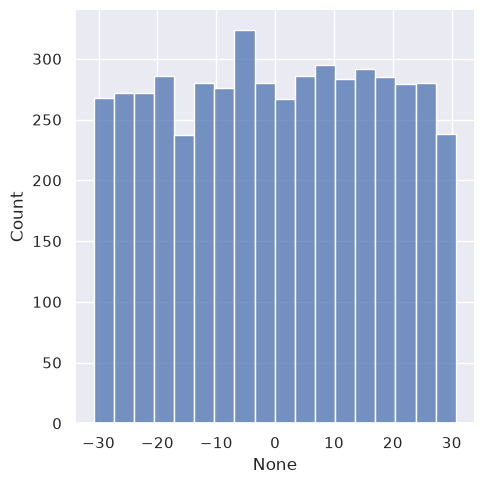

In [41]:
sns.displot(x=payment_lm.resid)

In [42]:
payment = [group['last_login_days'] for name,group in netflix.groupby('payment_method')]
stats.kruskal(*payment)

KruskalResult(statistic=np.float64(5.143635156293392), pvalue=np.float64(0.27287458461027253))

Payment method also doesn't appear to be a sigificant predictor of last login time.

In [43]:
genre_lm = smf.ols('last_login_days ~ C(favorite_genre)', data=netflix).fit()
genre_lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        last_login_days   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.173
Date:                Tue, 20 Oct 2026   Prob (F-statistic):              0.317
Time:                        11:20:20   Log-Likelihood:                -21412.
No. Observations:                5000   AIC:                         4.284e+04
Df Residuals:                    4993   BIC:                         4.288e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           30.0617      0.664     45.263      0.000      28.760      31.364
C(favorite_genre)[T.Comedy]          0.0653      0.943      0.069      0.945      -1.784       1.915
C(favorite_genre)[T.Documentary]     0.8670      0.929      0.933      0.351      -0.954       2.688
C(favorite_genre)[T.Drama]           0.0929      0.928      0.100      0.920      -1.727       1.913
C(favorite_genre)[T.Horror]          0.1992      0.934      0.213      0.831      -1.632       2.030
C(favorite_genre)[T.Romance]         0.3907      0.930      0.420      0.674      -1.433       2.214
C(favorite_genre)[T.Sci-Fi]         -1.4297      0.932     -1.535      0.125      -3.256       0.397
==============================================================================
Omnibus:                     3839.722   Durbin-Watson:                   1.993
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              294.766
Skew:                          -0.028   Prob(JB):                     9.83e-65
Kurtosis:                       1.812   Cond. No.                         7.96
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

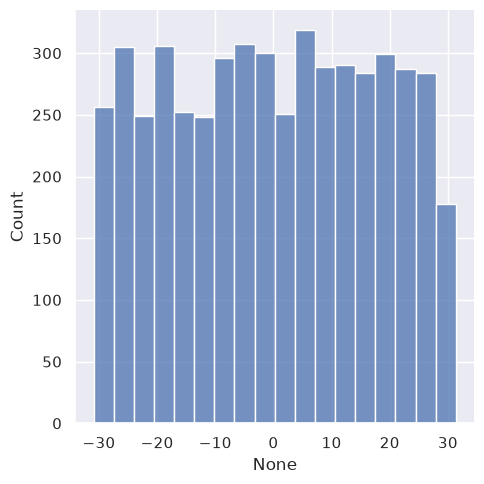

In [44]:
sns.displot(x=genre_lm.resid)

In [45]:
genre = [group['last_login_days'] for name,group in netflix.groupby('favorite_genre')]
stats.kruskal(*genre)

KruskalResult(statistic=np.float64(7.141873834781007), pvalue=np.float64(0.3079259523588829))

Genre also doesn't seem to be a significant predictor of last login time, and thus of churn. None of the categorical variables seem to be.